In [1]:
# ============================================================
# COMP9417 Air Quality Project
# STEP 8 – CLASSIFICATION MODELLING (CO Level Prediction)
# ============================================================
# Models used:
#   - Logistic Regression
#   - Random Forest Classifier
#   - XGBoost Classifier
#
# Target:
#   CO(GT) discretised into 3 classes (low / mid / high), (labels = 0,1,2)
#
# Forecast horizons:
#   1h, 6h, 12h, 24h ahead
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from sklearn.metrics import accuracy_score, classification_report

# XGBoost
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv(
    "/Users/lin/Downloads/GroupProject_FiveGuys/Dataset/AirQuality_clean.csv",
    parse_dates=["timestamp"]
).sort_values("timestamp")

df = df.set_index("timestamp")


In [3]:
def discretise_co(x):
    if x < 1.5:
        return 0  # low
    elif x < 2.5:
        return 1  # mid
    else:
        return 2  # high

df["CO_class"] = df["CO(GT)"].apply(discretise_co)


In [4]:
LAGS = [1, 3, 6, 12, 24]

for lag in LAGS:
    df[f"CO_lag{lag}"] = df["CO(GT)"].shift(lag)

# Calendar features
df["hour"] = df.index.hour
df["weekday"] = df.index.dayofweek
df["month"] = df.index.month
df["is_weekend"] = df["weekday"].isin([5, 6]).astype(int)

df = df.dropna()


In [10]:
horizons = [1, 6, 12, 24]  # hours ahead

TARGET_COLS = ["CO(GT)", "NOx(GT)", "C6H6(GT)", "NO2(GT)"]

for h in horizons:
    for col in TARGET_COLS:
        if col in df.columns:
            df[f"{col}_t+{h}"] = df[col].shift(-h)

    
def co_class(x):
    if x < 1.5:
        return 0
    elif x < 2.5:
        return 1
    else:
        return 2

for h in horizons:
    df[f"CO_class_t+{h}"] = df[f"CO_t+{h}"].apply(co_class)
    
df = df.ffill().bfill()
df = df.drop(columns=["Unnamed: 15", "Unnamed: 16"], errors='ignore')


In [11]:
HORIZONS = [1, 6, 12, 24]

In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        multi_class="multinomial"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        random_state=42
    )
}


In [13]:
def evaluate_classifier(model_name, y_true, y_pred, horizon):
    print(f"\n{model_name} — {horizon}h ahead")
    print("-" * 40)

    # Text metrics
    print(classification_report(
        y_true, y_pred,
        target_names=["Low", "Mid", "High"],
        digits=3
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low", "Mid", "High"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} — Confusion Matrix ({horizon}h)")
    plt.tight_layout()
    plt.show()



 Forecast Horizon: 1 hour(s)


/Users/lin/opt/anaconda3/envs/OpenCV/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Logistic Regression — 1h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       497
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1867
   macro avg      1.000     1.000     1.000      1867
weighted avg      1.000     1.000     1.000      1867



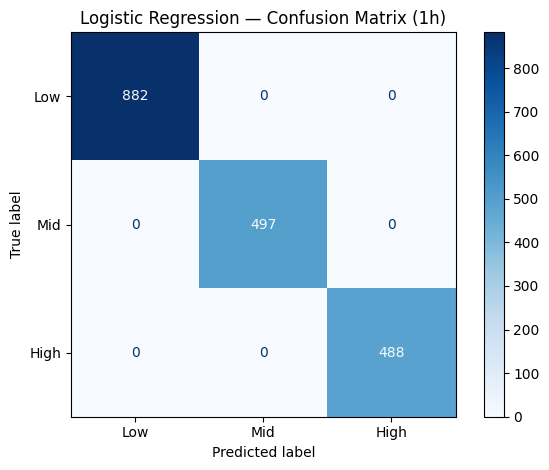


Random Forest — 1h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       497
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1867
   macro avg      1.000     1.000     1.000      1867
weighted avg      1.000     1.000     1.000      1867



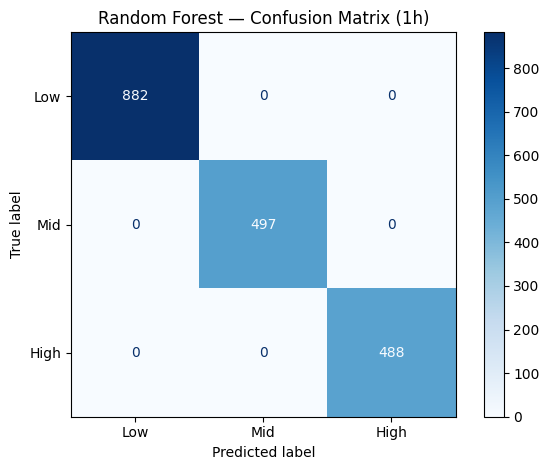


XGBoost — 1h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       497
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1867
   macro avg      1.000     1.000     1.000      1867
weighted avg      1.000     1.000     1.000      1867



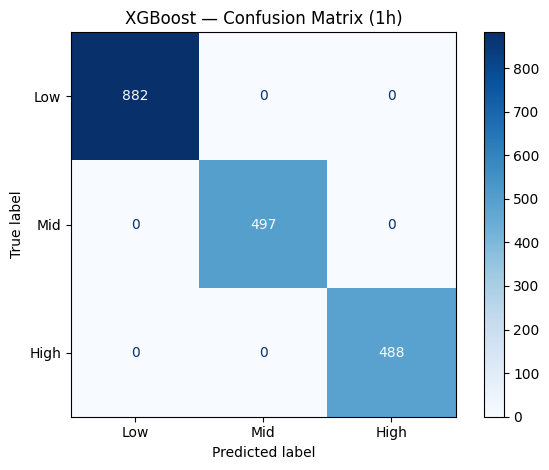


 Forecast Horizon: 6 hour(s)

Logistic Regression — 6h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       496
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1866
   macro avg      1.000     1.000     1.000      1866
weighted avg      1.000     1.000     1.000      1866



/Users/lin/opt/anaconda3/envs/OpenCV/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


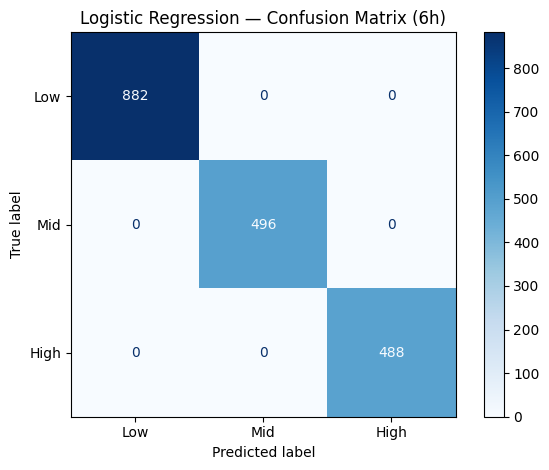


Random Forest — 6h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       496
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1866
   macro avg      1.000     1.000     1.000      1866
weighted avg      1.000     1.000     1.000      1866



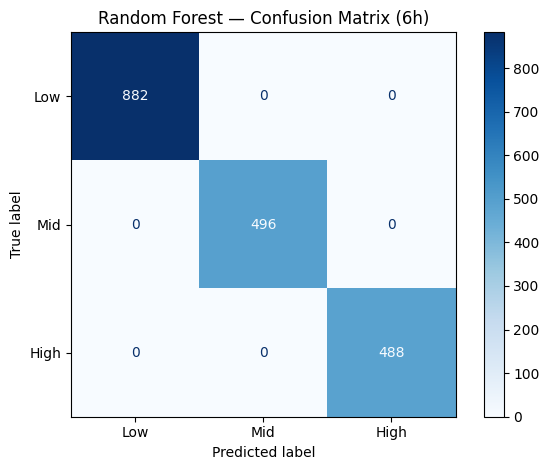


XGBoost — 6h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       496
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1866
   macro avg      1.000     1.000     1.000      1866
weighted avg      1.000     1.000     1.000      1866



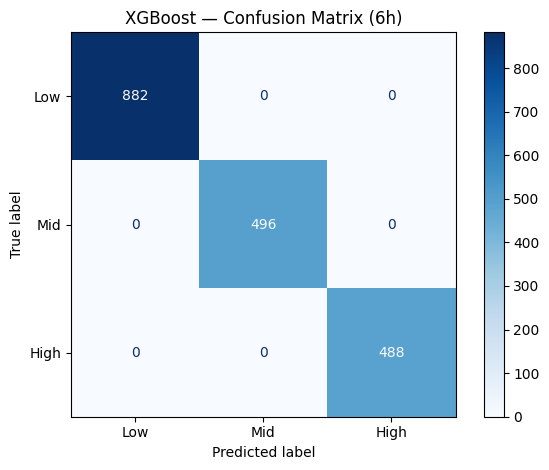


 Forecast Horizon: 12 hour(s)

Logistic Regression — 12h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       495
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1865
   macro avg      1.000     1.000     1.000      1865
weighted avg      1.000     1.000     1.000      1865



/Users/lin/opt/anaconda3/envs/OpenCV/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


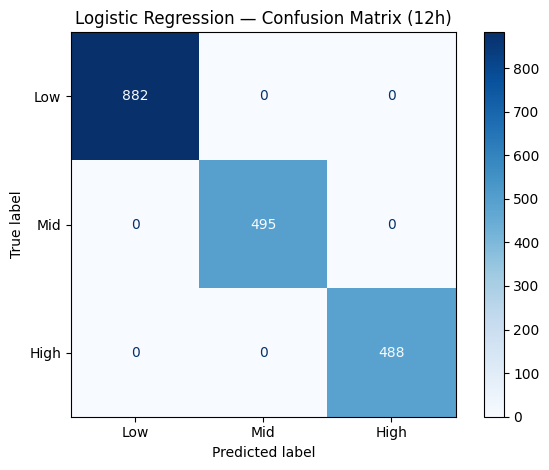


Random Forest — 12h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       495
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1865
   macro avg      1.000     1.000     1.000      1865
weighted avg      1.000     1.000     1.000      1865



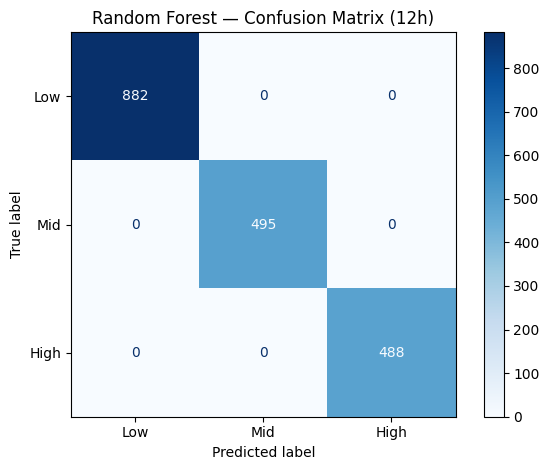


XGBoost — 12h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       882
         Mid      1.000     1.000     1.000       495
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1865
   macro avg      1.000     1.000     1.000      1865
weighted avg      1.000     1.000     1.000      1865



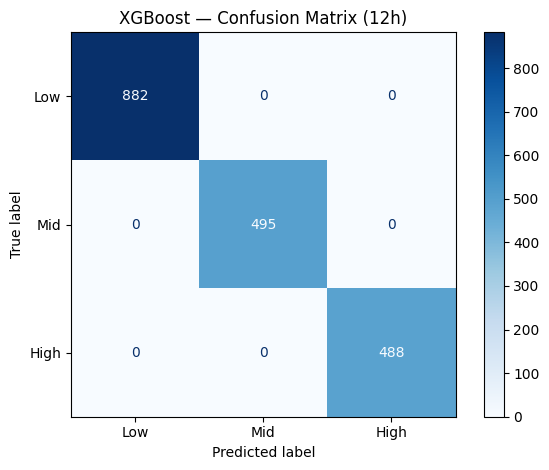


 Forecast Horizon: 24 hour(s)

Logistic Regression — 24h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     0.999     0.999       880
         Mid      0.998     1.000     0.999       494
        High      1.000     1.000     1.000       488

    accuracy                          0.999      1862
   macro avg      0.999     1.000     0.999      1862
weighted avg      0.999     0.999     0.999      1862



/Users/lin/opt/anaconda3/envs/OpenCV/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


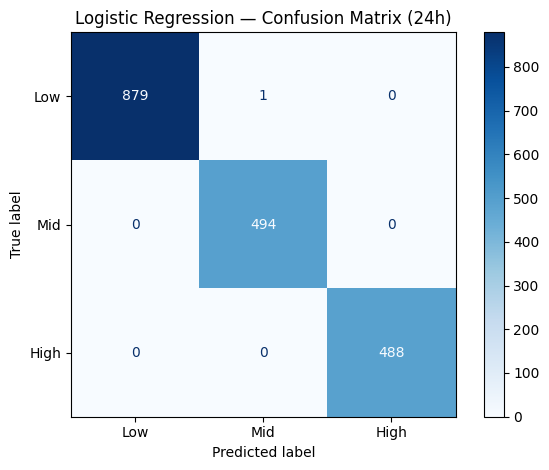


Random Forest — 24h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       880
         Mid      1.000     1.000     1.000       494
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1862
   macro avg      1.000     1.000     1.000      1862
weighted avg      1.000     1.000     1.000      1862



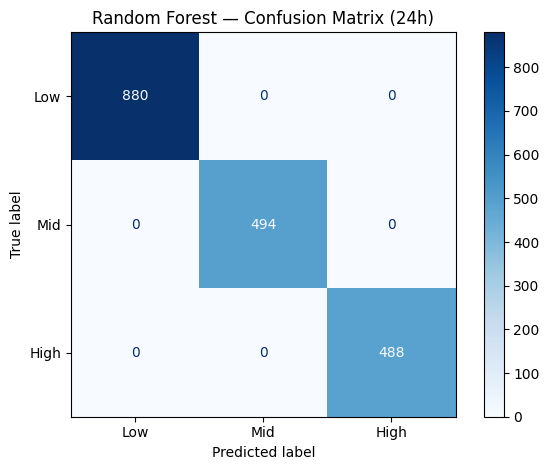


XGBoost — 24h ahead
----------------------------------------
              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       880
         Mid      1.000     1.000     1.000       494
        High      1.000     1.000     1.000       488

    accuracy                          1.000      1862
   macro avg      1.000     1.000     1.000      1862
weighted avg      1.000     1.000     1.000      1862



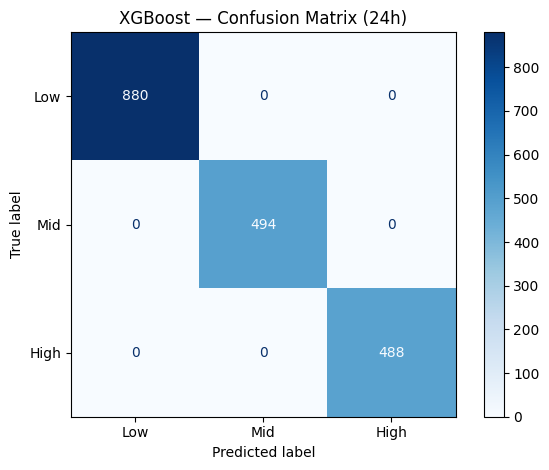

In [19]:
results = []

FEATURES = (
    df.select_dtypes(include=[np.number])
      .columns
      .difference(["CO(GT)", "CO_class"])
)

for h in HORIZONS:
    print(f"\n==============================")
    print(f" Forecast Horizon: {h} hour(s)")
    print(f"==============================")

    df_h = df.copy()
    df_h["target"] = df_h["CO_class"].shift(-h)
    df_h = df_h.dropna()

    # --- numeric-only features ---
    FEATURES = (
        df_h.select_dtypes(include=[np.number])
            .columns
            .difference(["CO(GT)", "CO_class", "target"])
    )

    X = df_h[FEATURES]
    y = df_h["target"]

    # Time-based split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, shuffle=False
    )

    # Scaling for Logistic Regression
    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    for name, model in models.items():

        if name == "Logistic Regression":
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_test_scaled)
        else:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

        # ---- evaluation ----
        evaluate_classifier(name, y_test, y_pred, horizon=h)



In [17]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


target
0.0    0.362696
2.0    0.348194
1.0    0.289110
Name: proportion, dtype: float64
target
0.0    0.472610
1.0    0.265306
2.0    0.262084
Name: proportion, dtype: float64
